# MACHINE LEARNING
## Prediksi Total Penjualan pada Dataset Retail Sales

**Nama:** Abdurrahman Hafidz
**Mata Kuliah:** Machine Learning

### Dataset
Retail Sales Dataset (`sales.csv`)

### Tujuan
Membangun model Machine Learning untuk memprediksi total nilai transaksi penjualan (`Total Amount`) berdasarkan data transaksi, jumlah barang yang dibeli (`Quantity`), harga per unit (`Price per Unit`), dan karakteristik customer.

### Jenis Machine Learning
Regression

## 1. Import Library

Bagian ini digunakan untuk memanggil library yang diperlukan selama proses pengolahan data, visualisasi, pembuatan model, dan evaluasi hasil prediksi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Lars
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

## 2. Membaca Dataset

Pada bagian ini, dataset `sales.csv` dibaca menggunakan Pandas. Pastikan file CSV berada di folder yang sama dengan notebook agar lebih mudah ditemukan.

In [2]:
df = pd.read_csv("sales.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 3. Memahami Struktur Dataset

Tahap ini dilakukan untuk mengetahui jumlah data, nama kolom, tipe data, dan informasi umum dataset sebelum dilakukan pengolahan lebih lanjut.

In [3]:
print("Informasi dataset:")
df.info()

print("\nJumlah baris dan kolom:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nStatistik deskriptif:")
display(df.describe())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Jumlah baris dan kolom: (1000, 9)

Nama kolom:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Statistik deskriptif:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


## 4. Pemeriksaan Kualitas Data

Pemeriksaan dilakukan untuk mengetahui apakah terdapat nilai kosong dan data duplikat. Hasil pemeriksaan digunakan untuk menentukan apakah dataset membutuhkan pembersihan sebelum masuk ke tahap analisis.

In [4]:
print("Jumlah nilai kosong setiap kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

Jumlah nilai kosong setiap kolom:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Jumlah baris duplikat: 0


## 5. Data Cleaning dan Feature Engineering

Kolom tanggal diubah ke format datetime agar informasi waktu bisa diolah. Selanjutnya, bulan, tanggal, dan hari dalam minggu diambil sebagai fitur tambahan. Kolom identitas transaksi dan pelanggan tidak digunakan sebagai fitur prediksi karena hanya berfungsi sebagai penanda.

In [5]:
# Membuat salinan dataset
data = df.copy()

# Mengubah kolom tanggal ke format datetime
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Membuat fitur waktu
data["Month"] = data["Date"].dt.month
data["Day"] = data["Date"].dt.day
data["DayOfWeek"] = data["Date"].dt.dayofweek

# Menghapus baris yang tanggalnya tidak valid
data = data.dropna(subset=["Date"])

# Menghapus data duplikat
data = data.drop_duplicates()

# Menghapus kolom identitas dan tanggal asli
data = data.drop(
    columns=["Transaction ID", "Customer ID", "Date"],
    errors="ignore"
)

print("Ukuran data setelah persiapan:", data.shape)
display(data.head())

Ukuran data setelah persiapan: (1000, 9)


,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Day,DayOfWeek
0,Male,34,Beauty,3,50,150,11,24,4
1,Female,26,Clothing,2,500,1000,2,27,0
2,Male,50,Electronics,1,30,30,1,13,4
3,Male,37,Clothing,1,500,500,5,21,6
4,Male,30,Beauty,2,50,100,5,6,5


## 6. Exploratory Data Analysis (EDA)

Eksplorasi data dilakukan untuk memahami pola penjualan, distribusi total transaksi, dan jumlah transaksi pada setiap kategori produk. Visualisasi ini membantu memberikan gambaran awal sebelum model Machine Learning dibuat.

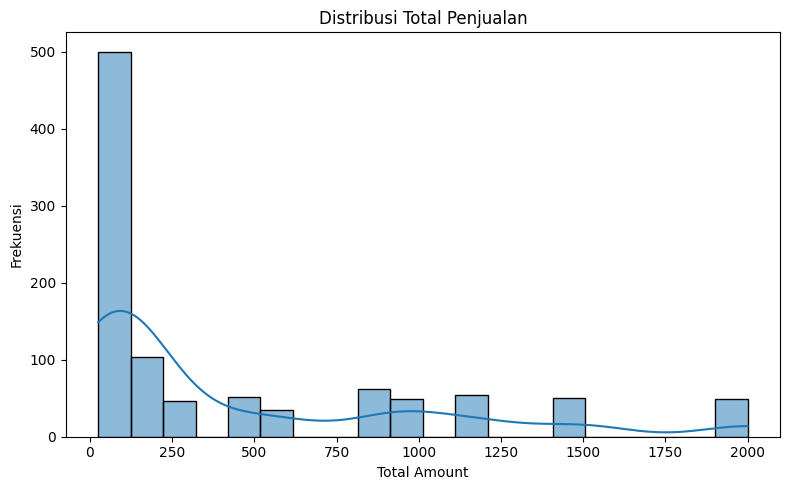

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="Total Amount", bins=20, kde=True)

plt.title("Distribusi Total Penjualan")
plt.xlabel("Total Amount")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

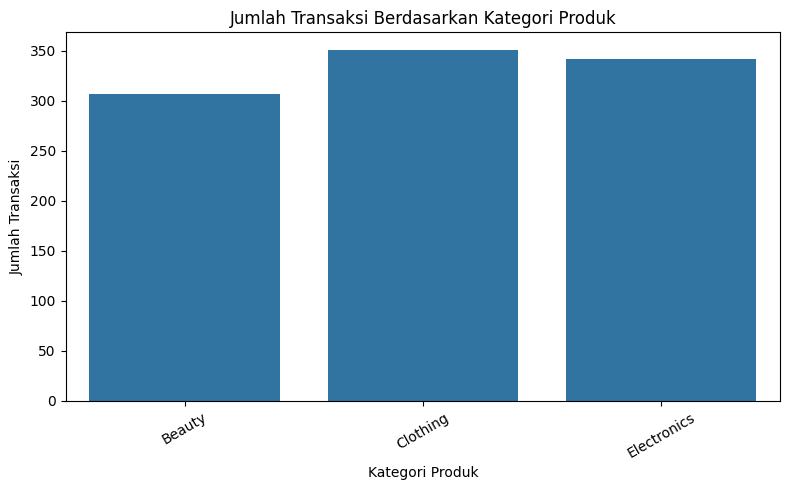

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Product Category")

plt.title("Jumlah Transaksi Berdasarkan Kategori Produk")
plt.xlabel("Kategori Produk")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

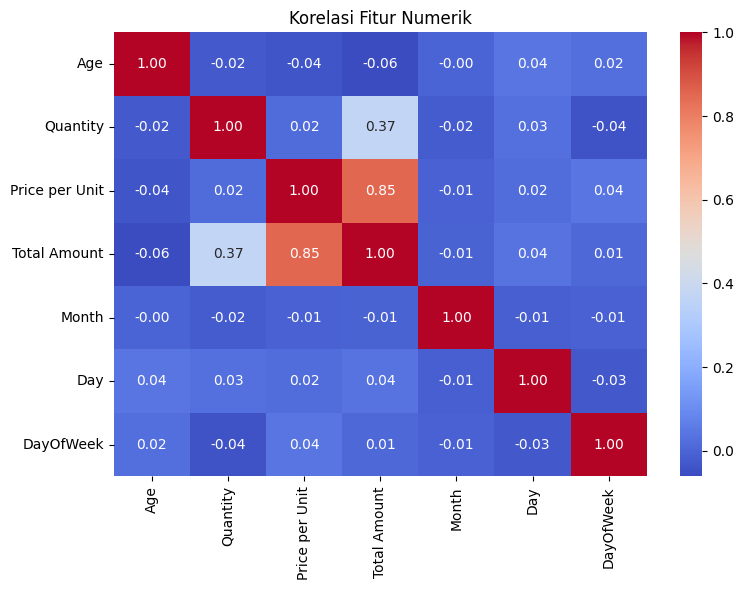

In [8]:
plt.figure(figsize=(8, 6))

kolom_numerik = data.select_dtypes(include="number")
sns.heatmap(
    kolom_numerik.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

## 7. Menentukan Fitur dan Target

Fitur (`X`) merupakan variabel yang digunakan model untuk menghasilkan prediksi, sedangkan target (`y`) adalah nilai yang ingin diprediksi. Pada proyek ini, target yang digunakan adalah `Total Amount`.

In [9]:
# Menghapus baris dengan target kosong
data = data.dropna(subset=["Total Amount"])

# Menentukan fitur dan target
X = data.drop(columns=["Total Amount"])
y = data["Total Amount"]

# Menentukan kolom numerik dan kategorikal
kolom_numerik = X.select_dtypes(include=["number"]).columns.tolist()
kolom_kategorikal = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Fitur numerik:", kolom_numerik)
print("Fitur kategorikal:", kolom_kategorikal)
print("Jumlah data:", len(X))

Fitur numerik: ['Age', 'Quantity', 'Price per Unit', 'Month', 'Day', 'DayOfWeek']
Fitur kategorikal: ['Gender', 'Product Category']
Jumlah data: 1000


## 8. Membagi Data Training dan Testing

Dataset dibagi menjadi data training sebesar 80% dan data testing sebesar 20%. Data training digunakan untuk melatih model, sedangkan data testing digunakan untuk mengevaluasi kemampuan model terhadap data yang tidak digunakan saat pelatihan.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 800
Jumlah data testing: 200


## 9. Preprocessing Data

Fitur numerik diproses menggunakan imputasi median dan standardisasi. Fitur kategorikal diproses dengan mengisi nilai kosong menggunakan kategori yang paling sering muncul, kemudian diubah menjadi format numerik menggunakan One-Hot Encoding. Pipeline memastikan tahapan preprocessing dipelajari dari data training.

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerik",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            kolom_numerik
        ),
        (
            "kategorikal",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            kolom_kategorikal
        )
    ]
)

## 10. Pembuatan dan Pelatihan Model

Tiga algoritma regresi akan dibandingkan, yaitu Linear Regression, LARS, dan Gradient Boosting Regressor. Setiap model menggunakan preprocessing yang sama agar perbandingan hasil evaluasi lebih konsisten.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "LARS": Lars(n_nonzero_coefs=1),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

trained_models = {}
predictions = {}

for nama, algoritma in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algoritma)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[nama] = pipeline
    predictions[nama] = y_pred

    print(f"{nama} berhasil dilatih.")

Linear Regression berhasil dilatih.
LARS berhasil dilatih.
Gradient Boosting berhasil dilatih.


## 11. Evaluasi Model

Evaluasi dilakukan menggunakan MAE, MSE, RMSE, dan R². MAE, MSE, dan RMSE digunakan untuk mengukur kesalahan prediksi, sedangkan R² menunjukkan seberapa besar variasi target yang dapat dijelaskan model. Untuk MAE, MSE, dan RMSE, nilai yang lebih kecil umumnya lebih baik. Untuk R², nilai yang lebih tinggi umumnya lebih baik.

In [14]:
hasil_evaluasi = []

for nama, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    hasil_evaluasi.append({
        "Model": nama,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

hasil_df = pd.DataFrame(hasil_evaluasi)
display(hasil_df.round(3))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,175.562,43059.934,207.509,0.853
1,LARS,261.936,116454.408,341.254,0.602
2,Gradient Boosting,1.391,5.244,2.290,1.000


## 12. Perbandingan Hasil Model

Hasil evaluasi dari ketiga model ditampilkan dalam satu tabel agar perbedaan kinerjanya lebih mudah diamati. Model dengan nilai kesalahan yang lebih rendah dan nilai R² yang lebih tinggi dapat dipertimbangkan sebagai model dengan performa lebih baik pada data testing.

In [15]:
hasil_urut = hasil_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(hasil_urut.round(3))

model_terbaik = hasil_urut.iloc[0]["Model"]

print("Model dengan RMSE terendah:", model_terbaik)

,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,1.391,5.244,2.290,1.000
1,Linear Regression,175.562,43059.934,207.509,0.853
2,LARS,261.936,116454.408,341.254,0.602


Model dengan RMSE terendah: Gradient Boosting


## 13. Visualisasi Nilai Aktual dan Prediksi

Visualisasi ini membandingkan nilai `Total Amount` yang sebenarnya dengan nilai yang diprediksi oleh model. Semakin dekat titik-titik dengan garis diagonal, semakin dekat hasil prediksi dengan nilai aktual.

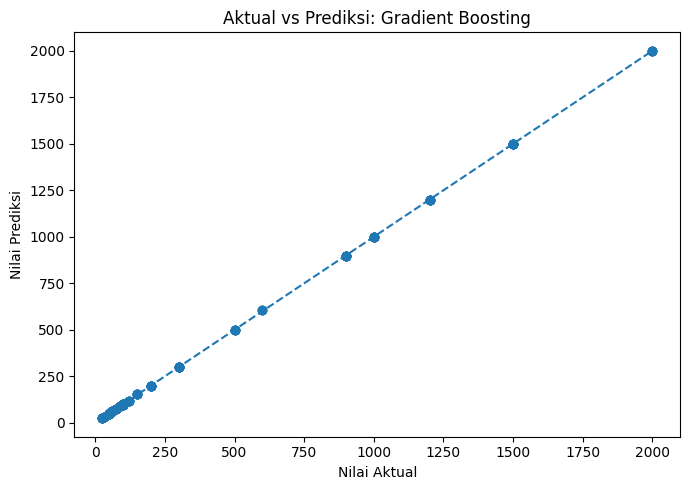

In [16]:
y_pred_terbaik = predictions[model_terbaik]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_terbaik, alpha=0.7)

nilai_min = min(y_test.min(), y_pred_terbaik.min())
nilai_max = max(y_test.max(), y_pred_terbaik.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.title(f"Aktual vs Prediksi: {model_terbaik}")
plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.tight_layout()
plt.show()

## 14. Kesimpulan

Berdasarkan proses pengolahan data dan evaluasi, ketiga algoritma regresi dibandingkan menggunakan MAE, MSE, RMSE, dan R². Model dengan RMSE terendah menjadi model terbaik berdasarkan kriteria tersebut pada data testing.

Hasil evaluasi perlu ditafsirkan dengan memperhatikan karakteristik dataset. Karena `Total Amount` memiliki hubungan perhitungan langsung dengan `Quantity` dan `Price per Unit`, performa model yang tinggi belum tentu menunjukkan kemampuan memprediksi perilaku penjualan pada kondisi baru. Pengujian pada data atau periode lain diperlukan untuk menilai kemampuan generalisasi model.